
# 05 — Final Evaluation

## SIADS 696 Milestone II

This notebook completes the final evaluation stage of the project by bringing together the supervised learning, unsupervised learning, and integration analyses.

The project investigates whether institution-level student debt burden can be predicted using historical institutional characteristics from the U.S. Department of Education's College Scorecard data.

The outcome is defined as:

$$
\text{debt\_burden} =
\log\left(
\frac{\text{GRAD\_DEBT\_MDN}}
{\text{MD\_EARN\_WNE\_P10}}
\right)
$$

The final modeling dataset contains **3,296 institutions** at the OPEID6 level, including **2,636 training institutions** and **660 held-out test institutions**.

### Notebook Goals

1. Verify the final datasets and previously selected modeling pipeline.
2. Evaluate the finalized model on the held-out test set.
3. Compare final model performance against relevant baselines.
4. Examine prediction errors and residual patterns.
5. Evaluate model performance across different institution types.
6. Conduct feature sensitivity and robustness analyses.
7. Investigate at least three specific prediction failures.
8. Generate final tables and figures for the project report.

### Evaluation Strategy

Model selection and hyperparameter tuning are based exclusively on training-set cross-validation results from the earlier notebooks.

The held-out test set is reserved for final evaluation and will not be used for model selection, hyperparameter tuning, or fitting preprocessing transformations.


In [1]:

# Standard library imports
import sys
import json
from pathlib import Path

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model loading and evaluation
import joblib
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Project directories
PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures" / "05_final_evaluation"
RESULTS_DIR = PROJECT_ROOT / "results" / "05_final_evaluation"

# Create output directories if they do not already exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
RANDOM_STATE = 42

# Consistent visualization settings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

print("Project root:", PROJECT_ROOT.resolve())
print("Processed data directory:", PROCESSED_DIR.resolve())
print("Figures directory:", FIGURES_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

Project root: C:\C\Users\froze\Documents\Homework\University of Michigan - Ann Arbor\SIADS 696 - Milestone II Project
Processed data directory: C:\C\Users\froze\Documents\Homework\University of Michigan - Ann Arbor\SIADS 696 - Milestone II Project\data\processed
Figures directory: C:\C\Users\froze\Documents\Homework\University of Michigan - Ann Arbor\SIADS 696 - Milestone II Project\figures\05_final_evaluation
Results directory: C:\C\Users\froze\Documents\Homework\University of Michigan - Ann Arbor\SIADS 696 - Milestone II Project\results\05_final_evaluation



## 1. Load and Verify the Prepared Datasets

The data preparation notebook established a common modeling dataset containing 35 approved predictors and the institution-level debt-burden outcome.

The data were divided into an 80% training set and a 20% held-out test set, with each OPEID6 institution appearing in only one partition.

Before conducting the final evaluation, we verify the dataset dimensions, institution identifiers, predictor consistency, and absence of target leakage.

The training dataset is used to verify the modeling configuration established in the earlier notebooks. The held-out test dataset will be evaluated only after the final pipeline has been confirmed.

In [2]:

# Define paths to the datasets produced in Notebook 1
modeling_path = PROCESSED_DIR / "modeling_dataset.csv"
train_path = PROCESSED_DIR / "train_dataset.csv"
test_path = PROCESSED_DIR / "test_dataset.csv"

# Verify that all expected dataset files exist
dataset_paths = {
    "Modeling dataset": modeling_path,
    "Training dataset": train_path,
    "Test dataset": test_path
}

for name, path in dataset_paths.items():
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

# Stop execution if any required dataset is unavailable
missing_files = [
    str(path)
    for path in dataset_paths.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Required dataset files are missing: {missing_files}"
    )

# Load the complete modeling dataset and training partition
# The test partition will be loaded after the final model is locked
modeling = pd.read_csv(modeling_path)
train = pd.read_csv(train_path)

# Define the institution identifier and prediction target
ID_COL = "OPEID6"
TARGET = "debt_burden"

# Identify the approved predictor columns
FEATURES = [
    col for col in train.columns
    if col not in [ID_COL, TARGET]
]

# Verify dataset structure
assert train[ID_COL].is_unique, "Duplicate training institution IDs found."
assert train[TARGET].notna().all(), "Missing training target values found."
assert len(FEATURES) == 35, "Unexpected number of predictor columns."

# Ensure the target components are not included as predictors
TARGET_SOURCE_COLUMNS = [
    "GRAD_DEBT_MDN",
    "MD_EARN_WNE_P10"
]

assert not set(TARGET_SOURCE_COLUMNS).intersection(FEATURES), (
    "Potential target leakage detected."
)

print("\nModeling dataset shape:", modeling.shape)
print("Training dataset shape:", train.shape)
print("Number of approved predictors:", len(FEATURES))
print("Unique training institutions:", train[ID_COL].nunique())

Modeling dataset: Found
Training dataset: Found
Test dataset: Found

Modeling dataset shape: (3296, 37)
Training dataset shape: (2636, 37)
Number of approved predictors: 35
Unique training institutions: 2636



## 2. Final Model Selection

The supervised learning and integration notebooks evaluated multiple modeling approaches using training-set cross-validation.

This section reviews the previously saved cross-validation results to determine which finalized pipeline should be evaluated on the held-out test set.

The comparison focuses on:

- Predictive performance of the supervised learning models.
- Performance of the selected supervised model with and without cluster-derived features.
- Variation in performance across cross-validation folds.
- Whether the integration approach provides a meaningful improvement over the supervised model alone.

The final model will be selected using these training-set results before examining held-out test performance.

In [3]:

# Paths to the supervised and integration results
supervised_results_dir = PROJECT_ROOT / "results" / "02_supervised"
integration_results_dir = PROJECT_ROOT / "results" / "04_integration"

# Load saved cross-validation model comparisons
supervised_comparison = pd.read_csv(
    supervised_results_dir / "model_comparison.csv"
)

integration_comparison = pd.read_csv(
    integration_results_dir / "integration_comparison.csv"
)

# Display the supervised learning comparison
print("SUPERVISED LEARNING MODEL COMPARISON")
display(supervised_comparison)

# Display the integration comparison
print("\nSUPERVISED VS. INTEGRATED MODEL COMPARISON")
display(integration_comparison)

# Examine the saved result columns
print("\nSupervised comparison columns:")
print(supervised_comparison.columns.tolist())

print("\nIntegration comparison columns:")
print(integration_comparison.columns.tolist())

SUPERVISED LEARNING MODEL COMPARISON


,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,Mean baseline,0.421900,0.011031,0.339361,0.009838,-0.001466,0.001428
1,Sector baseline,0.396537,0.014270,0.309512,0.011806,0.115551,0.021026
2,Sector × degree baseline,0.364965,0.016179,0.278324,0.010810,0.250700,0.035201
3,Ridge,0.290036,0.008628,0.216419,0.004899,0.526063,0.029605
4,Lasso,0.289855,0.008119,0.216151,0.004714,0.526716,0.027440
5,Elastic Net,0.290055,0.008307,0.216343,0.004675,0.526050,0.028112
6,Random Forest,0.275459,0.010261,0.199595,0.007454,0.573093,0.016316
7,LightGBM,0.274104,0.006765,0.199821,0.005945,0.577115,0.012529



SUPERVISED VS. INTEGRATED MODEL COMPARISON


,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std,rmse_change_mean,rmse_change_sd,folds_improved,n_folds,paired_t,p_value,passes_rule
0,Mean baseline,0.421900,0.011031,0.339361,0.009838,-0.001466,0.001428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Sector baseline,0.396537,0.014270,0.309512,0.011806,0.115551,0.021026,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Cluster baseline (k = 4),0.368642,0.014092,0.280040,0.009465,0.235483,0.027961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Sector × degree baseline,0.364965,0.016179,0.278324,0.010810,0.250700,0.035201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LightGBM (supervised only),0.272298,0.009766,0.198444,0.008056,0.582752,0.017543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,LightGBM + clusters (k = 4),0.271793,0.008914,0.198243,0.007493,0.584280,0.015827,-0.000506,0.002174,4.0,5.0,-0.519943,0.630552,False
6,LightGBM + cluster membership,0.272108,0.009213,0.198235,0.007937,0.583306,0.016971,-0.000191,0.000736,3.0,5.0,-0.579420,0.593372,False
7,LightGBM + centroid distances,0.271538,0.009297,0.198059,0.008021,0.585061,0.016753,-0.000760,0.002300,4.0,5.0,-0.739238,0.500794,False
8,LightGBM + PCA scores,0.271839,0.007865,0.198033,0.008468,0.584003,0.017606,-0.000460,0.004458,3.0,5.0,-0.230511,0.829004,False



Supervised comparison columns:
['model', 'rmse_mean', 'rmse_std', 'mae_mean', 'mae_std', 'r2_mean', 'r2_std']

Integration comparison columns:
['model', 'rmse_mean', 'rmse_std', 'mae_mean', 'mae_std', 'r2_mean', 'r2_std', 'rmse_change_mean', 'rmse_change_sd', 'folds_improved', 'n_folds', 'paired_t', 'p_value', 'passes_rule']



### 2.1 Final Model Selection Results

The supervised learning analysis compared baseline models, regularized linear regression models, Random Forest, and LightGBM. LightGBM achieved the lowest mean cross-validation RMSE among the supervised candidates.

The integration analysis subsequently evaluated whether incorporating unsupervised representations improved LightGBM's predictive performance. These representations included cluster membership, centroid distances, PCA scores, and combined cluster features.

In the integration comparison, the supervised-only LightGBM model achieved:

- Mean CV RMSE: 0.272298 ± 0.009766
- Mean CV MAE: 0.198444 ± 0.008056
- Mean CV R²: 0.582752 ± 0.017543

Although the integrated variants produced small numerical improvements in mean RMSE, none passed the improvement criterion established in Notebook 4.

The largest mean RMSE reduction was obtained using centroid-distance features (0.000760), but this improvement was small relative to its fold-to-fold variability and was not statistically significant in the reported paired test (p = 0.500794).

**Final decision:** Retain the supervised-only LightGBM pipeline for held-out test evaluation.

This decision prioritizes predictive performance, model simplicity, and evidence of reliable improvement rather than selecting an integrated model based on a marginal reduction in mean cross-validation error.

The held-out test set was not used in this selection decision.

In [4]:

# Identify the supervised-only LightGBM model from Notebook 4
selected_model_name = "LightGBM (supervised only)"

selected_row = integration_comparison.loc[
    integration_comparison["model"] == selected_model_name
]

# Confirm that the expected model exists exactly once
assert len(selected_row) == 1, (
    "Expected exactly one supervised-only LightGBM result."
)

# Verify that none of the integrated alternatives passed
integrated_rows = integration_comparison.loc[
    integration_comparison["model"].str.startswith("LightGBM +")
]

assert not integrated_rows["passes_rule"].fillna(False).astype(bool).any(), (
    "An integrated model passed the improvement rule. "
    "Review the model-selection decision."
)

# Display the selected model's cross-validation performance
selected_cv = selected_row.iloc[0]

print("FINAL SELECTED MODEL")
print("-" * 50)
print("Model:", selected_model_name)
print(f"CV RMSE: {selected_cv['rmse_mean']:.6f}")
print(f"CV MAE:  {selected_cv['mae_mean']:.6f}")
print(f"CV R²:   {selected_cv['r2_mean']:.6f}")

# Record the model-selection decision for reproducibility
selection_record = {
    "selected_model": selected_model_name,
    "selection_basis": "Training-set cross-validation",
    "cv_rmse_mean": float(selected_cv["rmse_mean"]),
    "cv_rmse_std": float(selected_cv["rmse_std"]),
    "cv_mae_mean": float(selected_cv["mae_mean"]),
    "cv_r2_mean": float(selected_cv["r2_mean"]),
    "integration_improvement_rule_passed": False,
    "test_set_used_for_selection": False
}

selection_path = RESULTS_DIR / "final_model_selection.json"

with open(selection_path, "w", encoding="utf-8") as file:
    json.dump(selection_record, file, indent=4)

print("\nModel-selection record saved to:", selection_path)

FINAL SELECTED MODEL
--------------------------------------------------
Model: LightGBM (supervised only)
CV RMSE: 0.272298
CV MAE:  0.198444
CV R²:   0.582752

Model-selection record saved to: ..\results\05_final_evaluation\final_model_selection.json


In [5]:

# Locate the fitted model saved by Notebook 2
model_path = (
    PROJECT_ROOT
    / "results"
    / "02_supervised"
    / "selected_model.joblib"
)

# Verify that the model artifact exists
assert model_path.exists(), (
    f"Selected model artifact not found: {model_path}"
)

# Load the saved fitted model without retraining
final_model = joblib.load(model_path)

# Inspect the model type and structure
print("Saved model type:")
print(type(final_model))

print("\nSaved model representation:")
print(final_model)

# If the artifact is an sklearn Pipeline, inspect its steps
if hasattr(final_model, "named_steps"):
    print("\nPipeline steps:")
    for step_name, estimator in final_model.named_steps.items():
        print(f"{step_name}: {type(estimator).__name__}")

# Check whether the saved object supports prediction
print("\nSupports prediction:", hasattr(final_model, "predict"))

Saved model type:
<class 'sklearn.pipeline.Pipeline'>

Saved model representation:
Pipeline(steps=[('model',
                 LGBMRegressor(colsample_bytree=np.float64(0.4305629572798979),
                               learning_rate=np.float64(0.0056496258399535565),
                               min_child_samples=29, n_estimators=963, n_jobs=1,
                               num_leaves=39, random_state=42,
                               reg_lambda=np.float64(0.001186494478357996),
                               subsample=np.float64(0.7560465291496405),
                               subsample_freq=1, verbose=-1))])

Pipeline steps:
model: LGBMRegressor

Supports prediction: True


In [6]:

# Examine the feature representation expected by the saved model
print("MODEL FEATURE REQUIREMENTS")
print("-" * 60)

# Number of features used when the model was fitted
if hasattr(final_model, "n_features_in_"):
    print("Expected feature count:", final_model.n_features_in_)

# Feature names recorded by the fitted LightGBM estimator
lightgbm_model = final_model.named_steps["model"]

if hasattr(lightgbm_model, "feature_name_"):
    model_features = lightgbm_model.feature_name_

    print("\nModel feature names:")
    print(model_features)

    print("\nNumber of model features:", len(model_features))

# Compare against the prepared training dataset
print("\nPrepared dataset feature count:", len(FEATURES))

print("\nPrepared dataset feature names:")
print(FEATURES)

# Inspect data types to identify categorical or transformed inputs
print("\nTraining predictor data types:")
display(train[FEATURES].dtypes.value_counts())

MODEL FEATURE REQUIREMENTS
------------------------------------------------------------
Expected feature count: 35

Model feature names:
['CONTROL', 'REGION', 'PREDDEG', 'HIGHDEG', 'NUMBRANCH', 'UGDS', 'UGDS_WHITE', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_AIAN', 'UGDS_NHPI', 'UGDS_2MOR', 'UGDS_NRA', 'UGDS_UNKN', 'PPTUG_EF', 'PCTPELL', 'PCTFLOAN', 'ADM_RATE', 'SAT_AVG', 'TUITIONFEE_IN', 'TUITIONFEE_OUT', 'NET_PRICE', 'COST_OF_ATTENDANCE', 'COST_IS_ACADEMIC_YEAR', 'NUM_PROGRAMS', 'NUM_CREDENTIAL_LEVELS', 'HAS_CERTIFICATE', 'HAS_ASSOCIATE', 'HAS_BACHELOR', 'HAS_POSTBACC_CERT', 'HAS_MASTER', 'HAS_DOCTORAL', 'HAS_FIRST_PROFESSIONAL', 'HAS_GRAD_CERT']

Number of model features: 35

Prepared dataset feature count: 35

Prepared dataset feature names:
['CONTROL', 'REGION', 'PREDDEG', 'HIGHDEG', 'NUMBRANCH', 'UGDS', 'UGDS_WHITE', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_AIAN', 'UGDS_NHPI', 'UGDS_2MOR', 'UGDS_NRA', 'UGDS_UNKN', 'PPTUG_EF', 'PCTPELL', 'PCTFLOAN', 'ADM_RATE', 'SAT_AVG'

float64    35
Name: count, dtype: int64


## 3. Final Held-Out Test Evaluation

The final supervised-only LightGBM model was selected using training-set cross-validation results. The integrated alternatives did not satisfy the improvement criterion established in Notebook 4.

We now evaluate the previously fitted LightGBM pipeline on the held-out test set of 660 institutions.

This evaluation provides an estimate of how well the selected model generalizes to institutions that were not included in model development.

We report three regression metrics:

- **Root Mean Squared Error (RMSE):** Measures prediction error while placing greater emphasis on large errors.
- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and observed debt burden.
- **R²:** Measures the proportion of variation in the observed target explained by the model relative to a constant-mean prediction.

Because the target is the natural logarithm of the debt-to-earnings ratio, RMSE and MAE are expressed in log-ratio units.

The held-out test set is evaluated only after final model selection. Test results will not be used to retune the model or change the selected modeling approach.

In [7]:

# Load the held-out test dataset for final evaluation
test = pd.read_csv(test_path)

# Verify the expected number of held-out institutions
assert len(test) == 660, (
    f"Expected 660 test institutions, found {len(test)}."
)

# Verify that institution identifiers are unique
assert test[ID_COL].is_unique, (
    "Duplicate institution IDs found in the test set."
)

# Verify that training and test institutions do not overlap
train_ids = set(train[ID_COL])
test_ids = set(test[ID_COL])

assert train_ids.isdisjoint(test_ids), (
    "Training and test institution IDs overlap."
)

# Verify that all expected predictors are available
assert all(feature in test.columns for feature in FEATURES), (
    "One or more expected predictors are missing from the test set."
)

# Verify that the saved model expects the same feature order
model_features = final_model.named_steps["model"].feature_name_

assert list(model_features) == FEATURES, (
    "Saved model feature names do not match the prepared dataset."
)

# Separate predictors and observed target values
X_test = test[FEATURES].copy()
y_test = test[TARGET].copy()

# Verify that all observed test outcomes are available
assert y_test.notna().all(), (
    "Missing target values found in the test set."
)

print("HELD-OUT TEST DATA VALIDATION")
print("-" * 50)
print("Test institutions:", len(test))
print("Predictors:", X_test.shape[1])
print("Training/test overlap:", len(train_ids.intersection(test_ids)))
print("Missing target values:", y_test.isna().sum())
print("Feature order matches saved model:", True)

HELD-OUT TEST DATA VALIDATION
--------------------------------------------------
Test institutions: 660
Predictors: 35
Training/test overlap: 0
Missing target values: 0
Feature order matches saved model: True


In [8]:

# Generate predictions using the previously fitted LightGBM pipeline
# Do not fit or tune the model using the held-out test data
y_pred = final_model.predict(X_test)

# Calculate final regression performance metrics
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

# Create a summary table of held-out test performance
test_metrics = pd.DataFrame({
    "model": ["LightGBM (supervised only)"],
    "n_test": [len(y_test)],
    "rmse": [test_rmse],
    "mae": [test_mae],
    "r2": [test_r2]
})

print("FINAL HELD-OUT TEST PERFORMANCE")
display(test_metrics)

# Save the final evaluation metrics
test_metrics.to_csv(
    RESULTS_DIR / "final_test_metrics.csv",
    index=False
)

# Save institution-level predictions for later diagnostics
test_predictions = pd.DataFrame({
    ID_COL: test[ID_COL].values,
    "actual_debt_burden": y_test.values,
    "predicted_debt_burden": y_pred
})

# Calculate signed and absolute prediction errors
test_predictions["residual"] = (
    test_predictions["actual_debt_burden"]
    - test_predictions["predicted_debt_burden"]
)

test_predictions["absolute_error"] = (
    test_predictions["residual"].abs()
)

# Save predictions for residual, subgroup, and failure analyses
test_predictions.to_csv(
    RESULTS_DIR / "final_test_predictions.csv",
    index=False
)

print("\nSaved evaluation results to:")
print(RESULTS_DIR / "final_test_metrics.csv")
print(RESULTS_DIR / "final_test_predictions.csv")

FINAL HELD-OUT TEST PERFORMANCE


,model,n_test,rmse,mae,r2
0,LightGBM (supervised only),660,0.280856,0.192237,0.582527



Saved evaluation results to:
..\results\05_final_evaluation\final_test_metrics.csv
..\results\05_final_evaluation\final_test_predictions.csv



### 3.1 Held-Out Test Results and Interpretation

The selected supervised-only LightGBM model was evaluated on 660 held-out institutions using the same 35 predictors established during data preparation. The training and test sets contained no overlapping institution identifiers.

The final model achieved the following held-out test performance:

- **RMSE:** 0.280856
- **MAE:** 0.192237
- **R²:** 0.582527

These results were generally consistent with the training-set cross-validation estimates (RMSE = 0.272298, MAE = 0.198444, R² = 0.582752).

Held-out RMSE increased by approximately 3.1% relative to cross-validation, while MAE decreased by approximately 3.1%. The difference in R² was negligible.

The model therefore appears to generalize reasonably well to unseen institutions from the held-out sample, without a substantial deterioration in overall predictive performance.

An R² of approximately 0.583 indicates that the model explains about 58.3% of the variation in the log debt-to-earnings ratio relative to predicting the test-set mean.

However, the remaining prediction error indicates that important differences in institutional debt burden are not fully captured by the available predictors.

Because the target is log-transformed, RMSE and MAE should be interpreted in log-ratio units rather than dollars or percentage points.

The model was not retrained, retuned, or reselected using the held-out test results.


## 4. Final Model Comparison

This section consolidates the model-comparison results from the supervised learning and integration stages.

The purpose is to document how the selected LightGBM model compares with simpler baselines, regularized linear regression, Random Forest, and alternative models incorporating unsupervised features.

All models in the development comparison are evaluated using training-set cross-validation metrics. The held-out test results are reported separately for the selected model.

This distinction preserves the role of the test set as an independent final evaluation rather than a dataset for selecting among competing models.


In [9]:

# Combine the supervised and integration comparison results
# while avoiding duplicate supervised-only and baseline rows

supervised_table = supervised_comparison.copy()
supervised_table["category"] = "Supervised / Baseline"

# Include only integrated variants and the cluster baseline
integration_table = integration_comparison.loc[
    integration_comparison["model"].str.startswith("LightGBM +")
    | integration_comparison["model"].str.startswith("Cluster baseline")
].copy()

integration_table["category"] = "Unsupervised Integration"

# Keep the shared performance columns
comparison_columns = [
    "model",
    "category",
    "rmse_mean",
    "rmse_std",
    "mae_mean",
    "mae_std",
    "r2_mean",
    "r2_std"
]

final_cv_comparison = pd.concat(
    [
        supervised_table[comparison_columns],
        integration_table[comparison_columns]
    ],
    ignore_index=True
)

# Sort models from lowest to highest cross-validation RMSE
final_cv_comparison = final_cv_comparison.sort_values(
    "rmse_mean"
).reset_index(drop=True)

# Save the report-ready comparison table
final_cv_comparison.to_csv(
    RESULTS_DIR / "final_cv_model_comparison.csv",
    index=False
)

print("FINAL CROSS-VALIDATION MODEL COMPARISON")
display(final_cv_comparison.round(4))

print("\nSaved comparison table to:")
print(RESULTS_DIR / "final_cv_model_comparison.csv")

FINAL CROSS-VALIDATION MODEL COMPARISON


,model,category,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,LightGBM + centroid distances,Unsupervised Integration,0.2715,0.0093,0.1981,0.0080,0.5851,0.0168
1,LightGBM + clusters (k = 4),Unsupervised Integration,0.2718,0.0089,0.1982,0.0075,0.5843,0.0158
2,LightGBM + PCA scores,Unsupervised Integration,0.2718,0.0079,0.1980,0.0085,0.5840,0.0176
3,LightGBM + cluster membership,Unsupervised Integration,0.2721,0.0092,0.1982,0.0079,0.5833,0.0170
4,LightGBM,Supervised / Baseline,0.2741,0.0068,0.1998,0.0059,0.5771,0.0125
5,Random Forest,Supervised / Baseline,0.2755,0.0103,0.1996,0.0075,0.5731,0.0163
6,Lasso,Supervised / Baseline,0.2899,0.0081,0.2162,0.0047,0.5267,0.0274
7,Ridge,Supervised / Baseline,0.2900,0.0086,0.2164,0.0049,0.5261,0.0296
8,Elastic Net,Supervised / Baseline,0.2901,0.0083,0.2163,0.0047,0.5260,0.0281
9,Sector × degree baseline,Supervised / Baseline,0.3650,0.0162,0.2783,0.0108,0.2507,0.0352



Saved comparison table to:
..\results\05_final_evaluation\final_cv_model_comparison.csv


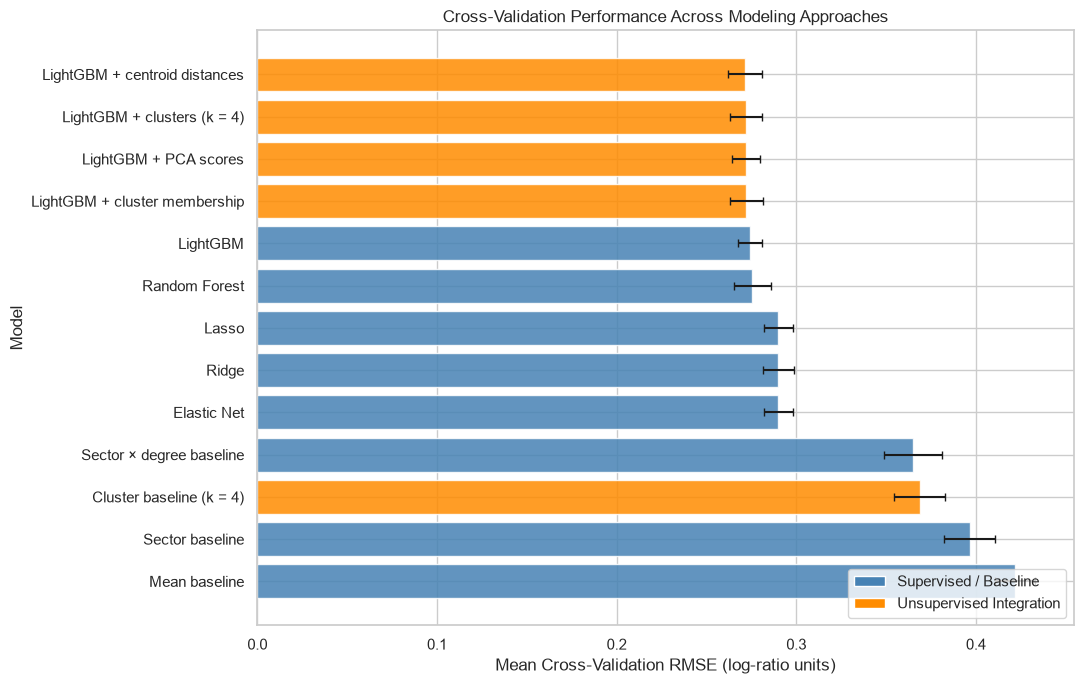

Saved figure to: ..\figures\05_final_evaluation\cv_model_comparison.png


In [10]:

# Plot mean cross-validation RMSE for all evaluated models
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = final_cv_comparison.sort_values(
    "rmse_mean",
    ascending=False
)

# Distinguish supervised and integrated approaches
colors = [
    "steelblue" if category == "Supervised / Baseline"
    else "darkorange"
    for category in plot_data["category"]
]

ax.barh(
    plot_data["model"],
    plot_data["rmse_mean"],
    xerr=plot_data["rmse_std"],
    color=colors,
    alpha=0.85,
    capsize=3
)

ax.set_xlabel("Mean Cross-Validation RMSE (log-ratio units)")
ax.set_ylabel("Model")
ax.set_title("Cross-Validation Performance Across Modeling Approaches")

# Add a legend for model categories
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="steelblue", label="Supervised / Baseline"),
    Patch(facecolor="darkorange", label="Unsupervised Integration")
]

ax.legend(handles=legend_elements, loc="lower right")

plt.tight_layout()

# Save the figure for the final report
figure_path = FIGURES_DIR / "cv_model_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


## 5. Prediction Diagnostics

This section examines the prediction errors of the selected LightGBM model on the held-out test set.

Although aggregate metrics such as RMSE, MAE, and R² summarize overall predictive performance, they do not fully describe how prediction errors vary across institutions.

We examine:

- The relationship between observed and predicted debt burden.
- The distribution of prediction residuals.
- Whether residuals exhibit systematic patterns across predicted values.
- The magnitude and direction of unusually large prediction errors.

Residuals are defined as:

**Residual = Observed Debt Burden − Predicted Debt Burden**

Positive residuals indicate that the model underestimated an institution's debt burden, while negative residuals indicate that the model overestimated it.

These diagnostics help identify potential model limitations and inform the subsequent subgroup and institutional failure-case analyses.

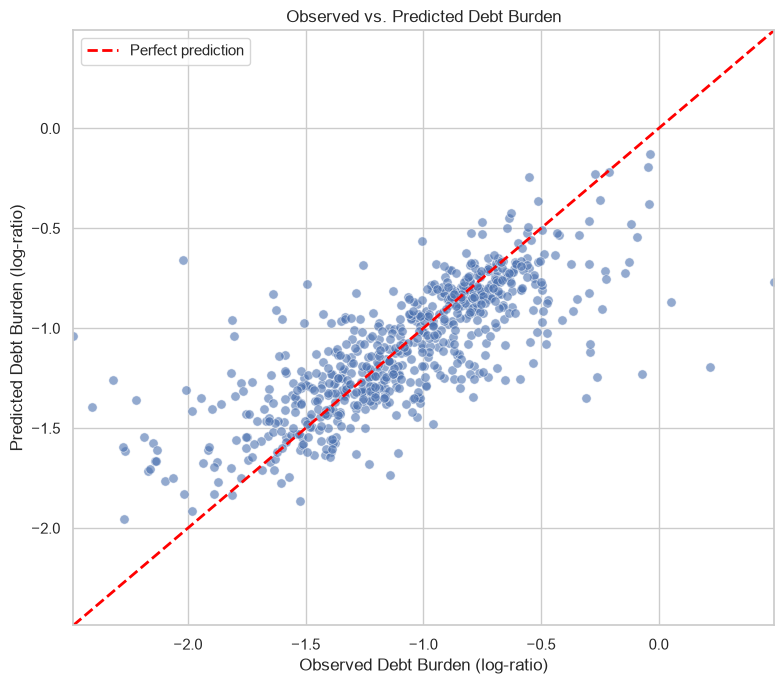

Saved figure to: ..\figures\05_final_evaluation\actual_vs_predicted.png


In [11]:

# Create a scatterplot comparing actual and predicted debt burden
fig, ax = plt.subplots(figsize=(8, 7))

sns.scatterplot(
    x=test_predictions["actual_debt_burden"],
    y=test_predictions["predicted_debt_burden"],
    alpha=0.6,
    s=45,
    ax=ax
)

# Determine a common plotting range for both axes
plot_min = min(
    test_predictions["actual_debt_burden"].min(),
    test_predictions["predicted_debt_burden"].min()
)

plot_max = max(
    test_predictions["actual_debt_burden"].max(),
    test_predictions["predicted_debt_burden"].max()
)

# Add the perfect-prediction reference line
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

ax.set_xlabel("Observed Debt Burden (log-ratio)")
ax.set_ylabel("Predicted Debt Burden (log-ratio)")
ax.set_title("Observed vs. Predicted Debt Burden")
ax.legend()

# Use equal axis limits for a fair visual comparison
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)

plt.tight_layout()

# Save the figure
figure_path = FIGURES_DIR / "actual_vs_predicted.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)

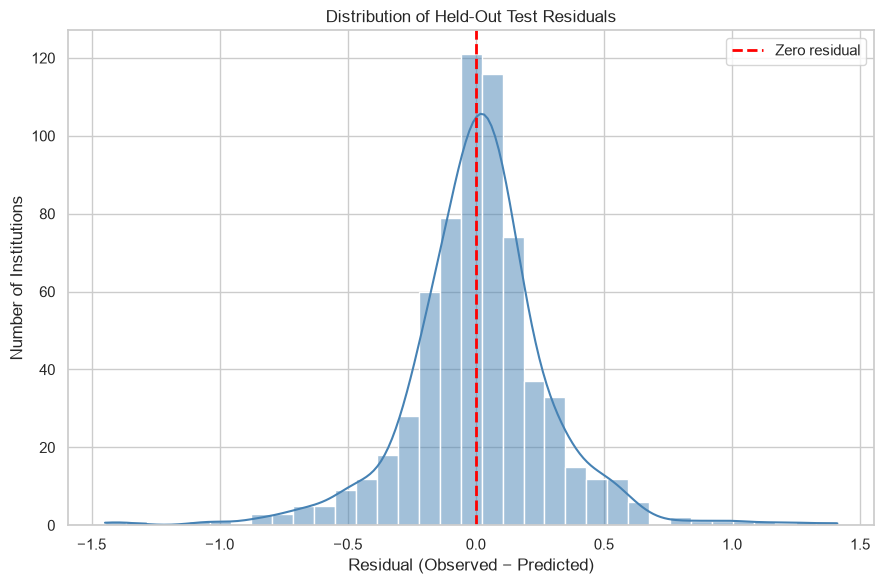

RESIDUAL SUMMARY


,Residual
count,660.000000
mean,0.012593
std,0.280786
min,-1.447307
25%,-0.124876
50%,0.014043
75%,0.139876
max,1.411616



Saved figure to: ..\figures\05_final_evaluation\residual_distribution.png


In [12]:

# Examine the distribution of prediction residuals
fig, ax = plt.subplots(figsize=(9, 6))

sns.histplot(
    test_predictions["residual"],
    bins=35,
    kde=True,
    color="steelblue",
    ax=ax
)

# Mark zero residual (perfect prediction)
ax.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero residual"
)

ax.set_xlabel("Residual (Observed − Predicted)")
ax.set_ylabel("Number of Institutions")
ax.set_title("Distribution of Held-Out Test Residuals")
ax.legend()

plt.tight_layout()

# Save the figure
figure_path = FIGURES_DIR / "residual_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

# Summarize the residual distribution
print("RESIDUAL SUMMARY")
display(
    test_predictions["residual"].describe().to_frame(
        name="Residual"
    )
)

print("\nSaved figure to:", figure_path)

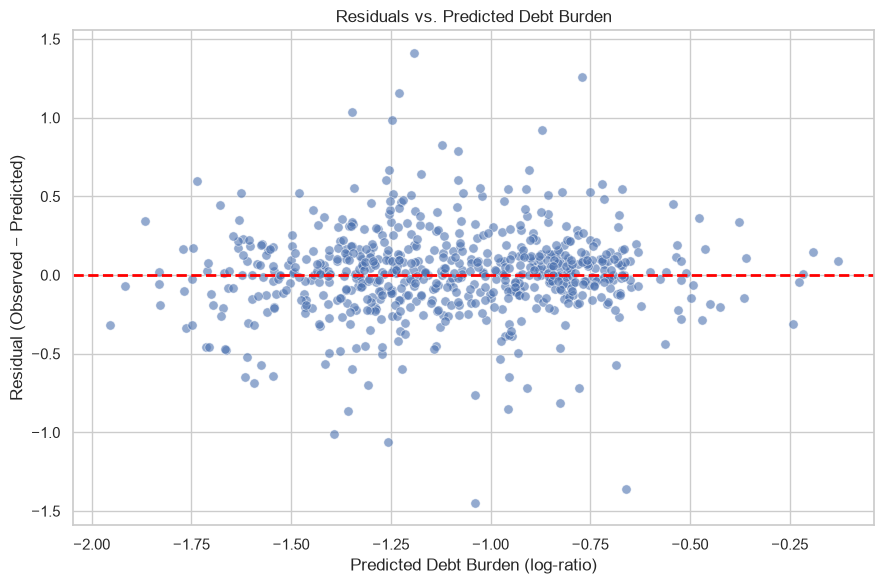

Saved figure to: ..\figures\05_final_evaluation\residuals_vs_predicted.png


In [13]:

# Check whether residuals vary systematically across predictions
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    x=test_predictions["predicted_debt_burden"],
    y=test_predictions["residual"],
    alpha=0.6,
    s=45,
    ax=ax
)

# Add a horizontal reference line at zero
ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

ax.set_xlabel("Predicted Debt Burden (log-ratio)")
ax.set_ylabel("Residual (Observed − Predicted)")
ax.set_title("Residuals vs. Predicted Debt Burden")

plt.tight_layout()

# Save the figure
figure_path = FIGURES_DIR / "residuals_vs_predicted.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


### 5.1 Interpretation of Prediction Diagnostics

The observed-versus-predicted scatterplot indicates that the LightGBM model captures a substantial portion of the variation in institutional debt burden, consistent with its held-out R² of approximately 0.583.

However, predictions tend to be concentrated toward the center of the observed target distribution. Institutions with unusually high or low debt burdens are not always predicted accurately, suggesting that the model has difficulty capturing some extreme outcomes.

The residual distribution is centered near zero, with a mean residual of 0.012593 and a median residual of 0.014043. These values indicate a small overall tendency toward underprediction, although the average signed error is close to zero.

The residual standard deviation is approximately 0.280786, consistent with the held-out RMSE of 0.280856.

Despite the relatively small average signed error, several institutions exhibit substantial prediction errors. Residuals range from -1.447307 to +1.411616 log-ratio units, indicating both pronounced overprediction and underprediction in individual cases.

The residuals-versus-predicted plot does not reveal an obvious strong linear trend across the predicted range. However, the presence of large positive and negative residuals suggests that predictive accuracy varies across institutions.

Overall, these diagnostics support the conclusion that LightGBM provides useful aggregate predictions but does not fully capture institution-specific differences in debt burden.

The largest errors warrant further investigation through subgroup analysis and specific institutional failure cases.


## 6. Subgroup Performance Analysis

Overall test-set performance can conceal differences in predictive accuracy across institutional subgroups.

This section evaluates whether the selected LightGBM model performs consistently across institutions with different characteristics.

We examine three dimensions:

1. **Institutional control (`CONTROL`):** Differences across institutional control categories.
2. **Predominant degree (`PREDDEG`):** Differences across institutions offering different predominant degree levels.
3. **Undergraduate enrollment (`UGDS`):** Differences across institution-size groups.

For each subgroup, we calculate:

- Number of institutions.
- Root Mean Squared Error (RMSE).
- Mean Absolute Error (MAE).
- Mean signed residual (bias).

Positive mean residuals indicate average underprediction, while negative values indicate average overprediction.

These comparisons are descriptive. Subgroup sample sizes and differences in outcome variability must be considered when interpreting differences in predictive performance.

In [14]:

# Combine test-set institution characteristics with saved predictions
subgroup_data = test[
    [ID_COL, "CONTROL", "PREDDEG", "UGDS"]
].merge(
    test_predictions,
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

# Verify that all held-out institutions are represented
assert len(subgroup_data) == len(test), (
    "Subgroup data does not contain all test institutions."
)

# Inspect category codes before assigning descriptive labels
print("INSTITUTIONAL CONTROL CATEGORIES")
display(
    subgroup_data["CONTROL"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("CONTROL")
    .reset_index(name="n_institutions")
)

print("\nPREDOMINANT DEGREE CATEGORIES")
display(
    subgroup_data["PREDDEG"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("PREDDEG")
    .reset_index(name="n_institutions")
)

print("\nUNDERGRADUATE ENROLLMENT SUMMARY")
display(subgroup_data["UGDS"].describe())

# Confirm that all predictions were matched correctly
print("\nTotal institutions:", len(subgroup_data))
print("Missing predictions:", subgroup_data["predicted_debt_burden"].isna().sum())

INSTITUTIONAL CONTROL CATEGORIES


,CONTROL,n_institutions
0,1.0,263
1,2.0,235
2,3.0,162



PREDOMINANT DEGREE CATEGORIES


,PREDDEG,n_institutions
0,1.0,203
1,2.0,146
2,3.0,311



UNDERGRADUATE ENROLLMENT SUMMARY


count      660.000000
mean      4463.839394
std       7560.551897
min         21.000000
25%        479.750000
50%       1593.500000
75%       4756.250000
max      66775.000000
Name: UGDS, dtype: float64


Total institutions: 660
Missing predictions: 0


In [15]:

# Define a reusable function for evaluating subgroup performance
def calculate_subgroup_metrics(data, group_column):
    results = []

    # Calculate performance metrics separately for each subgroup
    for group_name, group in data.groupby(group_column, observed=True):
        actual = group["actual_debt_burden"]
        predicted = group["predicted_debt_burden"]
        residuals = group["residual"]

        results.append({
            "group": group_name,
            "n_institutions": len(group),
            "rmse": np.sqrt(mean_squared_error(actual, predicted)),
            "mae": mean_absolute_error(actual, predicted),
            "mean_residual": residuals.mean()
        })

    return pd.DataFrame(results)


# Add descriptive labels for institutional control
control_labels = {
    1.0: "Public",
    2.0: "Private nonprofit",
    3.0: "Private for-profit"
}

subgroup_data["control_group"] = (
    subgroup_data["CONTROL"].map(control_labels)
)

# Add descriptive labels for predominant degree
degree_labels = {
    1.0: "Certificate",
    2.0: "Associate",
    3.0: "Bachelor's"
}

subgroup_data["degree_group"] = (
    subgroup_data["PREDDEG"].map(degree_labels)
)

# Divide institutions into four equally sized enrollment groups
subgroup_data["enrollment_group"] = pd.qcut(
    subgroup_data["UGDS"],
    q=4,
    labels=[
        "Q1: Smallest",
        "Q2: Small",
        "Q3: Large",
        "Q4: Largest"
    ]
)

# Calculate performance for each subgroup dimension
control_metrics = calculate_subgroup_metrics(
    subgroup_data, "control_group"
)

degree_metrics = calculate_subgroup_metrics(
    subgroup_data, "degree_group"
)

enrollment_metrics = calculate_subgroup_metrics(
    subgroup_data, "enrollment_group"
)

# Display the results
print("PERFORMANCE BY INSTITUTIONAL CONTROL")
display(control_metrics.round(4))

print("\nPERFORMANCE BY PREDOMINANT DEGREE")
display(degree_metrics.round(4))

print("\nPERFORMANCE BY UNDERGRADUATE ENROLLMENT")
display(enrollment_metrics.round(4))

# Save subgroup metrics for the final report
control_metrics.to_csv(
    RESULTS_DIR / "subgroup_control_metrics.csv",
    index=False
)

degree_metrics.to_csv(
    RESULTS_DIR / "subgroup_degree_metrics.csv",
    index=False
)

enrollment_metrics.to_csv(
    RESULTS_DIR / "subgroup_enrollment_metrics.csv",
    index=False
)

PERFORMANCE BY INSTITUTIONAL CONTROL


,group,n_institutions,rmse,mae,mean_residual
0,Private for-profit,162,0.3746,0.2882,0.0474
1,Private nonprofit,235,0.2686,0.1653,0.0094
2,Public,263,0.2169,0.1572,-0.0060



PERFORMANCE BY PREDOMINANT DEGREE


,group,n_institutions,rmse,mae,mean_residual
0,Associate,146,0.2696,0.1913,0.0576
1,Bachelor's,311,0.2172,0.1418,0.0132
2,Certificate,203,0.3632,0.2702,-0.0207



PERFORMANCE BY UNDERGRADUATE ENROLLMENT


,group,n_institutions,rmse,mae,mean_residual
0,Q1: Smallest,165,0.4115,0.3076,0.0224
1,Q2: Small,165,0.2660,0.1809,0.0031
2,Q3: Large,165,0.2028,0.1437,0.0173
3,Q4: Largest,165,0.1853,0.1368,0.0076


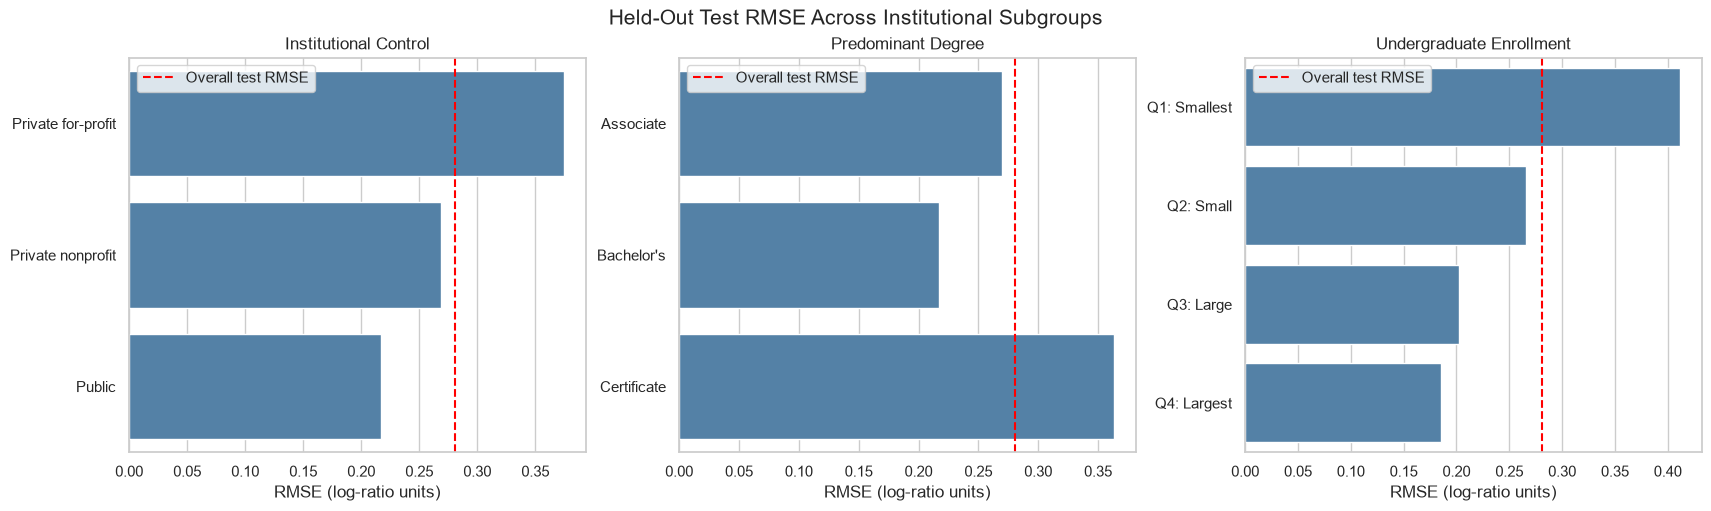

Saved figure to: ..\figures\05_final_evaluation\subgroup_rmse_comparison.png


In [16]:

# Combine subgroup performance results for visualization
plot_tables = []

for dimension, metrics in [
    ("Institutional Control", control_metrics),
    ("Predominant Degree", degree_metrics),
    ("Undergraduate Enrollment", enrollment_metrics)
]:
    table = metrics.copy()
    table["dimension"] = dimension
    plot_tables.append(table)

subgroup_plot_data = pd.concat(
    plot_tables,
    ignore_index=True
)

# Create separate panels for the three subgroup dimensions
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, dimension in zip(
    axes,
    [
        "Institutional Control",
        "Predominant Degree",
        "Undergraduate Enrollment"
    ]
):
    data = subgroup_plot_data.loc[
        subgroup_plot_data["dimension"] == dimension
    ]

    sns.barplot(
        data=data,
        x="rmse",
        y="group",
        color="steelblue",
        ax=ax
    )

    # Add the overall held-out RMSE as a reference
    ax.axvline(
        test_rmse,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Overall test RMSE"
    )

    ax.set_title(dimension)
    ax.set_xlabel("RMSE (log-ratio units)")
    ax.set_ylabel("")
    ax.legend()

fig.suptitle(
    "Held-Out Test RMSE Across Institutional Subgroups",
    fontsize=15
)

# Save the subgroup comparison figure
figure_path = FIGURES_DIR / "subgroup_rmse_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


### 6.1 Interpretation of Subgroup Performance

The subgroup analysis reveals substantial differences in prediction accuracy across institutional characteristics.

**Institutional Control:** Public institutions exhibited the lowest RMSE (0.2169), followed by private nonprofit institutions (0.2686). Private for-profit institutions had the highest RMSE (0.3746), approximately 73% higher than the public institution RMSE. For-profit institutions also had a positive mean residual of 0.0474, indicating a modest tendency toward underprediction.

**Predominant Degree:** Bachelor's-predominant institutions exhibited the lowest RMSE (0.2172), while associate-predominant institutions had an RMSE of 0.2696. Certificate-predominant institutions had the highest RMSE (0.3632) and MAE (0.2702), suggesting greater prediction difficulty for this subgroup.

**Undergraduate Enrollment:** Prediction errors decreased consistently across enrollment quartiles. The smallest institutions had an RMSE of 0.4115, compared with 0.1853 for the largest institutions. The smallest-institution RMSE was approximately 2.22 times the largest-institution RMSE.

These results indicate that overall model performance conceals substantial variation across institutional subgroups. The model performs relatively well for public, bachelor's-predominant, and larger institutions, while predictions are less accurate for private for-profit, certificate-predominant, and smaller institutions.

These findings are descriptive rather than causal. Institutional characteristics may overlap, and differences in subgroup RMSE may partly reflect differences in outcome variability or the prevalence of extreme observations.

The results motivate further investigation of whether the largest prediction errors are concentrated among institutions with these characteristics.


## 7. Feature Sensitivity and Robustness Analysis

This section investigates the sensitivity of the selected LightGBM model to its input features.

We use permutation feature importance to estimate how much predictive performance deteriorates when individual predictors are randomly shuffled while the fitted model remains unchanged.

For each feature, we:

1. Record the model's original held-out RMSE.
2. Randomly permute the feature values across test institutions.
3. Generate predictions using the unchanged fitted model.
4. Calculate the increase in RMSE relative to the original test performance.
5. Repeat the procedure to assess variability.

A larger increase in RMSE indicates that the model relies more heavily on that feature for accurate predictions in the evaluated sample.

Permutation importance measures predictive dependence rather than causal influence. Correlated predictors may share information, so permuting one feature may underestimate its importance when related features remain available.

This analysis is diagnostic only. No features are removed, model parameters are changed, or models are retrained based on held-out test results.

In [17]:

from sklearn.inspection import permutation_importance

# Measure how much prediction performance deteriorates
# when each feature is randomly shuffled.
#
# The model remains unchanged throughout this analysis.
# Negated RMSE is used because sklearn maximizes scoring metrics.

permutation_results = permutation_importance(
    estimator=final_model,
    X=X_test,
    y=y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Convert importance scores into a report-ready table.
# A positive value represents an increase in RMSE after permutation.
feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "rmse_increase_mean": permutation_results.importances_mean,
    "rmse_increase_std": permutation_results.importances_std
})

# Rank predictors by their average effect on RMSE
feature_importance = feature_importance.sort_values(
    "rmse_increase_mean",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES BY PERMUTATION IMPORTANCE")
display(feature_importance.head(15).round(6))

# Save complete feature-importance results
feature_importance.to_csv(
    RESULTS_DIR / "permutation_feature_importance.csv",
    index=False
)

print("\nSaved permutation importance results.")

TOP 15 FEATURES BY PERMUTATION IMPORTANCE


,feature,rmse_increase_mean,rmse_increase_std
0,PCTFLOAN,0.035941,0.004248
1,HIGHDEG,0.018464,0.002096
2,UGDS_ASIAN,0.015258,0.003245
3,TUITIONFEE_IN,0.014304,0.001705
4,PCTPELL,0.012645,0.002073
5,CONTROL,0.012176,0.001772
6,PREDDEG,0.009152,0.001275
7,NUM_PROGRAMS,0.006585,0.000792
8,REGION,0.006206,0.002366
9,TUITIONFEE_OUT,0.005854,0.001526



Saved permutation importance results.


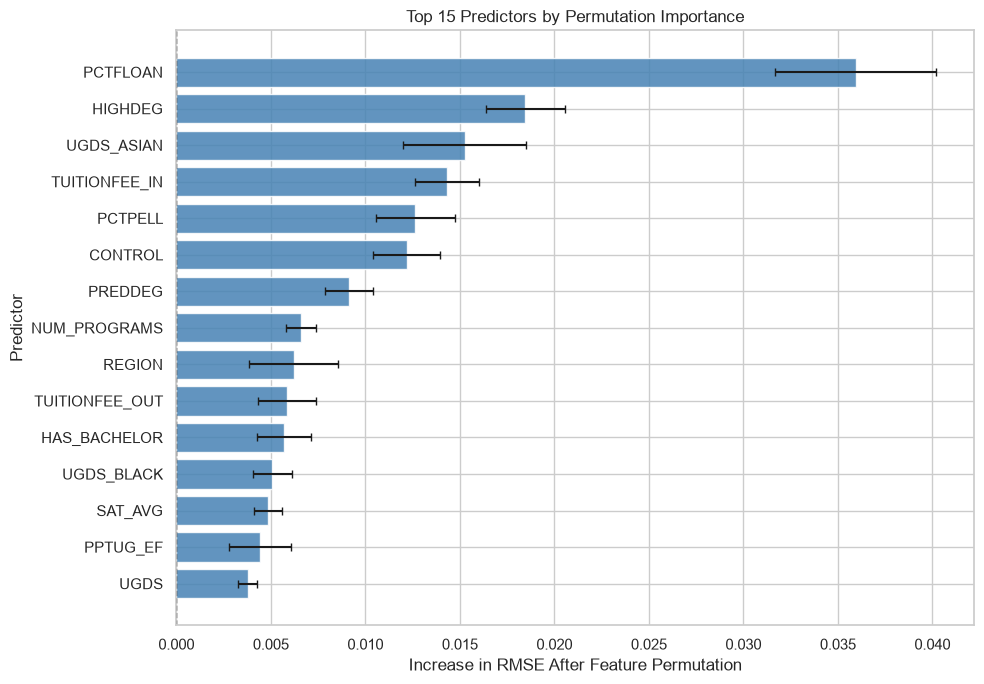

Saved figure to: ..\figures\05_final_evaluation\permutation_feature_importance.png


In [18]:

# Select the 15 predictors with the largest mean RMSE increase
top_features = feature_importance.head(15).sort_values(
    "rmse_increase_mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

# Display average RMSE increases with variability across permutations
ax.barh(
    top_features["feature"],
    top_features["rmse_increase_mean"],
    xerr=top_features["rmse_increase_std"],
    color="steelblue",
    alpha=0.85,
    capsize=3
)

# Mark zero importance for reference
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Increase in RMSE After Feature Permutation")
ax.set_ylabel("Predictor")
ax.set_title("Top 15 Predictors by Permutation Importance")

plt.tight_layout()

# Save the figure for the final report
figure_path = FIGURES_DIR / "permutation_feature_importance.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


### 7.1 Interpretation of Permutation Feature Importance

Permutation feature importance identified several institutional characteristics that contribute substantially to the selected LightGBM model's predictive performance.

The most influential predictor was `PCTFLOAN`, representing the proportion of students receiving federal loans. Permuting this variable increased held-out RMSE by approximately 0.03594 log-ratio units on average, a 12.8% increase relative to the original test RMSE of 0.280856.

Other influential predictors included highest degree offered (`HIGHDEG`), Asian undergraduate enrollment share (`UGDS_ASIAN`), in-state tuition and fees (`TUITIONFEE_IN`), Pell Grant recipient share (`PCTPELL`), institutional control (`CONTROL`), and predominant degree (`PREDDEG`).

These findings suggest that the model relies on information about student financing, institutional degree offerings, tuition, enrollment composition, and institutional structure when predicting debt burden.

The importance of demographic variables should be interpreted cautiously. Their predictive contribution does not establish a causal relationship between student demographic composition and debt burden. Such variables may also reflect broader institutional, geographic, or socioeconomic patterns.

Permutation importance measures predictive dependence rather than causal effects. Correlated features may share predictive information, and permuting features independently may produce combinations that are uncommon in the original data.

The analysis was conducted using the previously selected and fitted LightGBM model. No features were removed, model parameters were modified, or models were retrained based on these results.


### 7.2 Bootstrap Assessment of Evaluation Stability

To assess the stability of the final evaluation metrics, we use bootstrap resampling of the held-out test predictions.

Bootstrap resampling repeatedly draws institutions with replacement from the original held-out test sample. For each resample, we calculate RMSE, MAE, and R² using the already generated predictions.

This procedure provides an estimate of the sampling variability of the reported performance metrics.

We use 1,000 bootstrap resamples and report percentile-based 95% confidence intervals.

The fitted LightGBM model remains unchanged throughout this procedure. Bootstrap resampling is applied only to the existing observed outcomes and predictions.

These intervals describe uncertainty associated with resampling the held-out institutions. They do not account for uncertainty from model training, hyperparameter selection, or potential differences between the observed institutions and future populations.

In [19]:

# Assess the stability of final evaluation metrics through bootstrap
# resampling of the existing held-out predictions.

N_BOOTSTRAPS = 1000
rng = np.random.default_rng(RANDOM_STATE)

# Convert observed outcomes and predictions into NumPy arrays
actual_values = test_predictions["actual_debt_burden"].to_numpy()
predicted_values = test_predictions["predicted_debt_burden"].to_numpy()

n_test = len(actual_values)

bootstrap_results = []

for iteration in range(N_BOOTSTRAPS):
    # Sample institution indices with replacement
    sample_indices = rng.choice(
        n_test,
        size=n_test,
        replace=True
    )

    actual_sample = actual_values[sample_indices]
    predicted_sample = predicted_values[sample_indices]

    # Calculate metrics for the bootstrap sample
    bootstrap_results.append({
        "iteration": iteration + 1,
        "rmse": np.sqrt(
            mean_squared_error(actual_sample, predicted_sample)
        ),
        "mae": mean_absolute_error(
            actual_sample, predicted_sample
        ),
        "r2": r2_score(
            actual_sample, predicted_sample
        )
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

# Calculate percentile-based 95% confidence intervals
bootstrap_summary = []

for metric, point_estimate in [
    ("rmse", test_rmse),
    ("mae", test_mae),
    ("r2", test_r2)
]:
    lower = bootstrap_results[metric].quantile(0.025)
    upper = bootstrap_results[metric].quantile(0.975)

    bootstrap_summary.append({
        "metric": metric.upper(),
        "test_estimate": point_estimate,
        "ci_lower_95": lower,
        "ci_upper_95": upper
    })

bootstrap_summary = pd.DataFrame(bootstrap_summary)

print("BOOTSTRAP PERFORMANCE SUMMARY")
display(bootstrap_summary.round(6))

# Save bootstrap distributions and confidence intervals
bootstrap_results.to_csv(
    RESULTS_DIR / "bootstrap_metric_distributions.csv",
    index=False
)

bootstrap_summary.to_csv(
    RESULTS_DIR / "bootstrap_metric_summary.csv",
    index=False
)

print("\nSaved bootstrap robustness results.")

BOOTSTRAP PERFORMANCE SUMMARY


,metric,test_estimate,ci_lower_95,ci_upper_95
0,RMSE,0.280856,0.253026,0.306892
1,MAE,0.192237,0.176325,0.206425
2,R2,0.582527,0.516261,0.641805



Saved bootstrap robustness results.


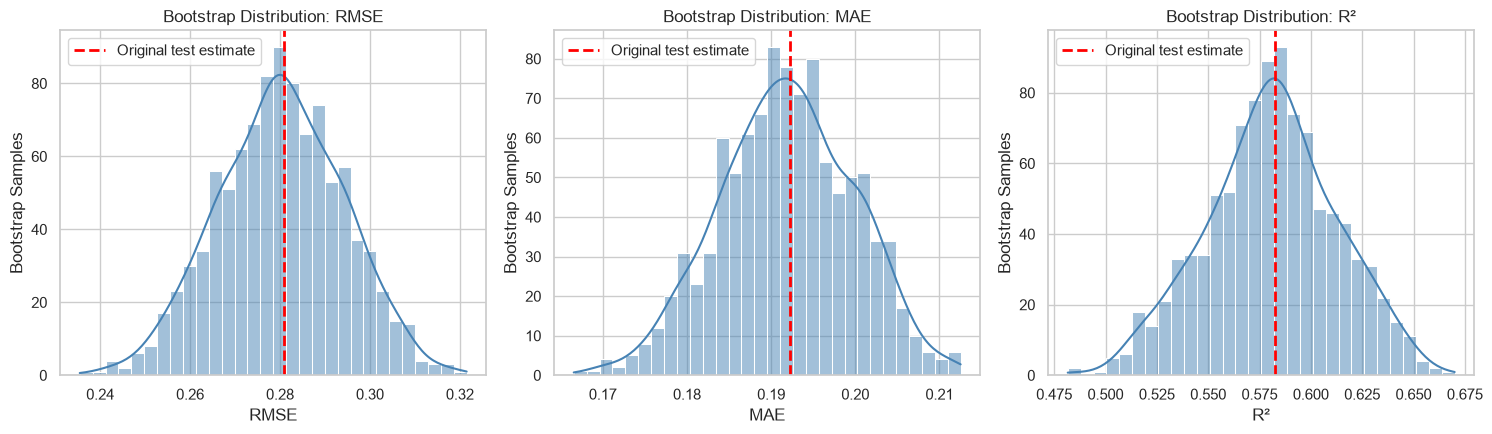

Saved figure to: ..\figures\05_final_evaluation\bootstrap_metric_distributions.png


In [20]:

# Create separate bootstrap distribution plots for each metric
metric_details = [
    ("rmse", test_rmse, "RMSE"),
    ("mae", test_mae, "MAE"),
    ("r2", test_r2, "R²")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (metric, estimate, label) in zip(
    axes, metric_details
):
    sns.histplot(
        bootstrap_results[metric],
        bins=30,
        kde=True,
        color="steelblue",
        ax=ax
    )

    # Mark the metric calculated on the original held-out sample
    ax.axvline(
        estimate,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Original test estimate"
    )

    ax.set_title(f"Bootstrap Distribution: {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Bootstrap Samples")
    ax.legend()

plt.tight_layout()

# Save the figure
figure_path = FIGURES_DIR / "bootstrap_metric_distributions.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


### 7.3 Interpretation of Bootstrap Robustness Results

Bootstrap resampling was performed using 1,000 samples drawn with replacement from the 660 held-out institutions. The fitted LightGBM model and its predictions remained unchanged throughout this analysis.

The resulting percentile-based 95% confidence intervals were:

- **RMSE:** 0.253026 to 0.306892, compared with a point estimate of 0.280856.
- **MAE:** 0.176325 to 0.206425, compared with a point estimate of 0.192237.
- **R²:** 0.516261 to 0.641805, compared with a point estimate of 0.582527.

The original held-out estimates were near the centers of their corresponding bootstrap distributions.

These results suggest that the model's overall performance is reasonably stable under resampling of the evaluated institutions, although some sampling variability remains.

The R² interval indicates that the proportion of explained variation could differ meaningfully across alternative samples of institutions.

These confidence intervals reflect uncertainty associated with the held-out sample rather than uncertainty in the model-training or hyperparameter-selection processes. They also do not establish that predictive performance is uniform across institutional subgroups.

Taken together, the bootstrap results support the reliability of the aggregate evaluation while reinforcing the importance of examining subgroup differences and individual prediction failures.


## 8. Investigation of Specific Model Failures

Although the selected LightGBM model achieves reasonable overall predictive performance, some held-out institutions exhibit substantial prediction errors.

This section investigates individual institutions for which predicted debt burden differs considerably from the observed value.

We identify the institutions with the largest absolute residuals and examine their institutional characteristics, including:

- Institutional control.
- Predominant degree.
- Undergraduate enrollment.
- Federal loan recipient share.
- Pell Grant recipient share.
- Tuition and fees.

We distinguish between underprediction and overprediction and investigate at least three specific failure cases.

The purpose is to identify plausible explanations for the observed errors and assess whether these examples reflect broader limitations identified through subgroup analysis.

These investigations are exploratory. Individual prediction errors do not establish causal relationships between institutional characteristics and debt burden.

In [21]:

# Combine the held-out institution characteristics with predictions
failure_data = test.merge(
    test_predictions,
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

# Add descriptive labels for institutional control and degree
failure_data["control_group"] = (
    failure_data["CONTROL"].map(control_labels)
)

failure_data["degree_group"] = (
    failure_data["PREDDEG"].map(degree_labels)
)

# Identify whether each prediction overestimates or underestimates
# the observed debt burden
failure_data["error_direction"] = np.where(
    failure_data["residual"] > 0,
    "Underprediction",
    "Overprediction"
)

# Sort institutions by the magnitude of their prediction errors
largest_errors = failure_data.sort_values(
    "absolute_error",
    ascending=False
)

# Select columns useful for investigating individual failures
failure_columns = [
    ID_COL,
    "control_group",
    "degree_group",
    "UGDS",
    "PCTFLOAN",
    "PCTPELL",
    "TUITIONFEE_IN",
    "actual_debt_burden",
    "predicted_debt_burden",
    "residual",
    "absolute_error",
    "error_direction"
]

# Display the 15 institutions with the largest errors
print("TOP 15 LARGEST ABSOLUTE PREDICTION ERRORS")
display(
    largest_errors[failure_columns]
    .head(15)
    .round(4)
)

# Save the complete ranked list for further investigation
largest_errors[failure_columns].to_csv(
    RESULTS_DIR / "largest_prediction_errors.csv",
    index=False
)

print("\nSaved ranked prediction errors.")

TOP 15 LARGEST ABSOLUTE PREDICTION ERRORS


,OPEID6,control_group,degree_group,UGDS,PCTFLOAN,PCTPELL,TUITIONFEE_IN,actual_debt_burden,predicted_debt_burden,residual,absolute_error,error_direction
496,1955.0,Private nonprofit,Bachelor's,1577.0,0.2773,0.8367,24270.0000,-2.4863,-1.0389,-1.4473,1.4473,Overprediction
370,22092.0,Private for-profit,Certificate,172.0,0.5652,0.5773,NaN,0.2189,-1.1927,1.4116,1.4116,Underprediction
502,10724.0,Private nonprofit,Bachelor's,370.0,0.6922,0.5249,10712.2378,-2.0220,-0.6600,-1.3620,1.3620,Overprediction
63,41831.0,Private for-profit,Certificate,81.0,0.5519,0.5974,NaN,0.4897,-0.7704,1.2602,1.2602,Underprediction
164,38383.0,Private for-profit,Associate,156.0,0.9086,0.6914,NaN,-0.0717,-1.2292,1.1575,1.1575,Underprediction
156,5618.0,Public,Certificate,4223.0,0.2479,0.6624,2644.0000,-2.3159,-1.2580,-1.0579,1.0579,Overprediction
147,36953.0,Private nonprofit,Certificate,140.0,0.4147,0.7868,NaN,-0.3092,-1.3477,1.0385,1.0385,Underprediction
482,10993.0,Private nonprofit,Certificate,322.0,0.3119,0.2779,NaN,-2.4054,-1.3924,-1.0130,1.0130,Overprediction
31,21719.0,Private nonprofit,Certificate,96.0,0.4396,0.1978,11520.0000,-0.2638,-1.2464,0.9826,0.9826,Underprediction
39,23608.0,Private for-profit,Associate,364.0,0.8661,0.7113,14882.0000,0.0513,-0.8701,0.9214,0.9214,Underprediction



Saved ranked prediction errors.


In [22]:

# Identify the five largest underpredictions
largest_underpredictions = failure_data.sort_values(
    "residual",
    ascending=False
).head(5)

# Identify the five largest overpredictions
largest_overpredictions = failure_data.sort_values(
    "residual",
    ascending=True
).head(5)

print("FIVE LARGEST UNDERPREDICTIONS")
display(
    largest_underpredictions[failure_columns].round(4)
)

print("\nFIVE LARGEST OVERPREDICTIONS")
display(
    largest_overpredictions[failure_columns].round(4)
)

FIVE LARGEST UNDERPREDICTIONS


,OPEID6,control_group,degree_group,UGDS,PCTFLOAN,PCTPELL,TUITIONFEE_IN,actual_debt_burden,predicted_debt_burden,residual,absolute_error,error_direction
370,22092.0,Private for-profit,Certificate,172.0,0.5652,0.5773,NaN,0.2189,-1.1927,1.4116,1.4116,Underprediction
63,41831.0,Private for-profit,Certificate,81.0,0.5519,0.5974,NaN,0.4897,-0.7704,1.2602,1.2602,Underprediction
164,38383.0,Private for-profit,Associate,156.0,0.9086,0.6914,NaN,-0.0717,-1.2292,1.1575,1.1575,Underprediction
147,36953.0,Private nonprofit,Certificate,140.0,0.4147,0.7868,NaN,-0.3092,-1.3477,1.0385,1.0385,Underprediction
31,21719.0,Private nonprofit,Certificate,96.0,0.4396,0.1978,11520.0,-0.2638,-1.2464,0.9826,0.9826,Underprediction



FIVE LARGEST OVERPREDICTIONS


,OPEID6,control_group,degree_group,UGDS,PCTFLOAN,PCTPELL,TUITIONFEE_IN,actual_debt_burden,predicted_debt_burden,residual,absolute_error,error_direction
496,1955.0,Private nonprofit,Bachelor's,1577.0,0.2773,0.8367,24270.0000,-2.4863,-1.0389,-1.4473,1.4473,Overprediction
502,10724.0,Private nonprofit,Bachelor's,370.0,0.6922,0.5249,10712.2378,-2.0220,-0.6600,-1.3620,1.3620,Overprediction
156,5618.0,Public,Certificate,4223.0,0.2479,0.6624,2644.0000,-2.3159,-1.2580,-1.0579,1.0579,Overprediction
482,10993.0,Private nonprofit,Certificate,322.0,0.3119,0.2779,NaN,-2.4054,-1.3924,-1.0130,1.0130,Overprediction
196,41650.0,Private for-profit,Certificate,383.0,0.3875,0.1937,NaN,-2.2200,-1.3568,-0.8632,0.8632,Overprediction



### 8.1 Selection of Institutional Failure Cases

The held-out prediction errors were ranked by absolute residual to identify institutions for further investigation.

Four institutions were selected to represent different failure patterns:

1. **OPEID6 1955:** A private nonprofit, bachelor's-predominant institution with the largest overprediction (residual = -1.4473).
2. **OPEID6 22092:** A small, private for-profit, certificate-predominant institution with the largest underprediction (residual = +1.4116).
3. **OPEID6 41831:** A very small, private for-profit, certificate-predominant institution with another substantial underprediction (residual = +1.2602).
4. **OPEID6 5618:** A public, certificate-predominant institution with a substantial overprediction (residual = -1.0579).

These examples were chosen to investigate both directions of prediction error and variation across institutional characteristics.

Because the target is defined as the natural logarithm of the median completer debt-to-median earnings ratio, exponentiating the observed and predicted values provides a more interpretable comparison on the original ratio scale.

The following analysis examines these cases in greater detail. Potential explanations are treated as hypotheses rather than established causes of prediction error.

In [23]:

# Select four institutions representing different failure patterns
selected_failure_ids = [1955, 22092, 41831, 5618]

failure_cases = failure_data.loc[
    failure_data[ID_COL].isin(selected_failure_ids)
].copy()

# Ensure that all selected institutions are present
assert len(failure_cases) == len(selected_failure_ids), (
    "One or more selected failure cases were not found."
)

# Convert log debt burden back to the original debt-to-earnings ratio
failure_cases["actual_ratio"] = np.exp(
    failure_cases["actual_debt_burden"]
)

failure_cases["predicted_ratio"] = np.exp(
    failure_cases["predicted_debt_burden"]
)

# Calculate the ratio of actual to predicted debt burden
# on the original debt-to-earnings scale
failure_cases["actual_to_predicted_ratio"] = (
    failure_cases["actual_ratio"]
    / failure_cases["predicted_ratio"]
)

# Display the selected failure cases
case_columns = [
    ID_COL,
    "control_group",
    "degree_group",
    "UGDS",
    "actual_debt_burden",
    "predicted_debt_burden",
    "actual_ratio",
    "predicted_ratio",
    "actual_to_predicted_ratio",
    "error_direction"
]

# Sort the complete DataFrame before selecting display columns
print("SELECTED INSTITUTIONAL FAILURE CASES")
display(
    failure_cases
    .sort_values("absolute_error", ascending=False)[case_columns]
    .round(4)
)

# Save the comparison table
failure_cases[case_columns].to_csv(
    RESULTS_DIR / "selected_failure_cases.csv",
    index=False
)

SELECTED INSTITUTIONAL FAILURE CASES


,OPEID6,control_group,degree_group,UGDS,actual_debt_burden,predicted_debt_burden,actual_ratio,predicted_ratio,actual_to_predicted_ratio,error_direction
496,1955.0,Private nonprofit,Bachelor's,1577.0,-2.4863,-1.0389,0.0832,0.3538,0.2352,Overprediction
370,22092.0,Private for-profit,Certificate,172.0,0.2189,-1.1927,1.2447,0.3034,4.1026,Underprediction
63,41831.0,Private for-profit,Certificate,81.0,0.4897,-0.7704,1.6319,0.4628,3.5261,Underprediction
156,5618.0,Public,Certificate,4223.0,-2.3159,-1.2580,0.0987,0.2842,0.3472,Overprediction


In [24]:

# Select institutional characteristics relevant to the failure analysis
characteristic_columns = [
    "UGDS",
    "PCTFLOAN",
    "PCTPELL",
    "TUITIONFEE_IN",
    "TUITIONFEE_OUT",
    "NET_PRICE",
    "COST_OF_ATTENDANCE",
    "ADM_RATE",
    "SAT_AVG",
    "NUM_PROGRAMS"
]

# Calculate held-out medians for comparison
test_medians = test[characteristic_columns].median()

# Extract the selected institutions' characteristics
case_characteristics = failure_cases[
    [ID_COL, "control_group", "degree_group"]
    + characteristic_columns
].copy()

print("SELECTED FAILURE CASE CHARACTERISTICS")
display(
    case_characteristics.round(4)
)

print("\nHELD-OUT TEST MEDIAN CHARACTERISTICS")
display(
    test_medians.to_frame(name="Test Median").round(4)
)

SELECTED FAILURE CASE CHARACTERISTICS


,OPEID6,control_group,degree_group,UGDS,PCTFLOAN,PCTPELL,TUITIONFEE_IN,TUITIONFEE_OUT,NET_PRICE,COST_OF_ATTENDANCE,ADM_RATE,SAT_AVG,NUM_PROGRAMS
63,41831.0,Private for-profit,Certificate,81.0,0.5519,0.5974,NaN,NaN,7661.0,12850.0,NaN,NaN,1.0
156,5618.0,Public,Certificate,4223.0,0.2479,0.6624,2644.0,4780.0,4786.0,10373.0,NaN,NaN,46.0
370,22092.0,Private for-profit,Certificate,172.0,0.5652,0.5773,NaN,NaN,15278.0,19267.0,NaN,NaN,1.0
496,1955.0,Private nonprofit,Bachelor's,1577.0,0.2773,0.8367,24270.0,24270.0,3067.0,31870.0,0.3366,1125.0,44.0



HELD-OUT TEST MEDIAN CHARACTERISTICS


,Test Median
UGDS,1593.5000
PCTFLOAN,0.5547
PCTPELL,0.4198
TUITIONFEE_IN,11234.0000
TUITIONFEE_OUT,17462.5000
NET_PRICE,15299.5000
COST_OF_ATTENDANCE,21060.5000
ADM_RATE,0.6595
SAT_AVG,1049.0000
NUM_PROGRAMS,30.0000



### 8.2 Detailed Investigation of Institutional Prediction Failures

Four held-out institutions were examined to illustrate different patterns of model failure. The observed and predicted log debt-burden values were exponentiated to obtain the corresponding debt-to-earnings ratios.

**Case 1 — OPEID6 1955: Largest Overprediction**

This private nonprofit, bachelor's-predominant institution had 1,577 undergraduate students, 44 programs, and a Pell Grant recipient share of 83.67%. Its reported net price was $3,067, substantially below the held-out median of $15,299.50.

The observed debt-to-earnings ratio was 0.0832, compared with a predicted ratio of 0.3538. The model therefore overpredicted the ratio by a factor of approximately 4.25.

The unusually low reported net price and other institutional characteristics may help explain why the observed debt burden was lower than predicted. However, the available data do not establish the cause of this discrepancy.

**Case 2 — OPEID6 22092: Largest Underprediction**

This private for-profit, certificate-predominant institution had 172 undergraduate students and one reported program.

Its observed debt-to-earnings ratio was 1.2447, compared with a predicted ratio of 0.3034. The observed ratio was approximately 4.10 times the predicted value.

The institution's small enrollment and limited program offerings may reflect institution-specific characteristics that are not fully represented by the available predictors. Missing tuition values also limit the descriptive information available for this case.

**Case 3 — OPEID6 41831: Extreme Underprediction**

This private for-profit, certificate-predominant institution had 81 undergraduate students and one reported program.

Its observed debt-to-earnings ratio was 1.6319, compared with a predicted ratio of 0.4628. The observed ratio was approximately 3.53 times the predicted value.

This case is consistent with the broader finding that small, certificate-predominant, and private for-profit institutions have relatively high prediction errors. Nevertheless, the available evidence does not establish which characteristics explain the discrepancy.

**Case 4 — OPEID6 5618: Overprediction at a Public Institution**

This public, certificate-predominant institution had 4,223 undergraduate students and 46 programs.

Its reported in-state tuition was $2,644, compared with the held-out median of $11,234.

The observed debt-to-earnings ratio was 0.0987, while the predicted ratio was 0.2842. The model overpredicted the ratio by a factor of approximately 2.88.

This case demonstrates that large prediction errors are not restricted to the institutional subgroups with the highest overall RMSE.

**Overall Findings**

These four cases illustrate substantial prediction errors in both directions. Two extreme underpredictions occurred among very small, private for-profit, certificate-predominant institutions, consistent with the subgroup analysis.

However, substantial overpredictions also occurred at private nonprofit and public institutions.

The results suggest that institutional-level predictors do not fully capture the factors associated with unusually high or low debt-to-earnings ratios.

Potential explanations include unobserved program-level differences, differences in student outcomes, and institutional characteristics not represented in the available features. These explanations remain hypotheses rather than established causal findings.

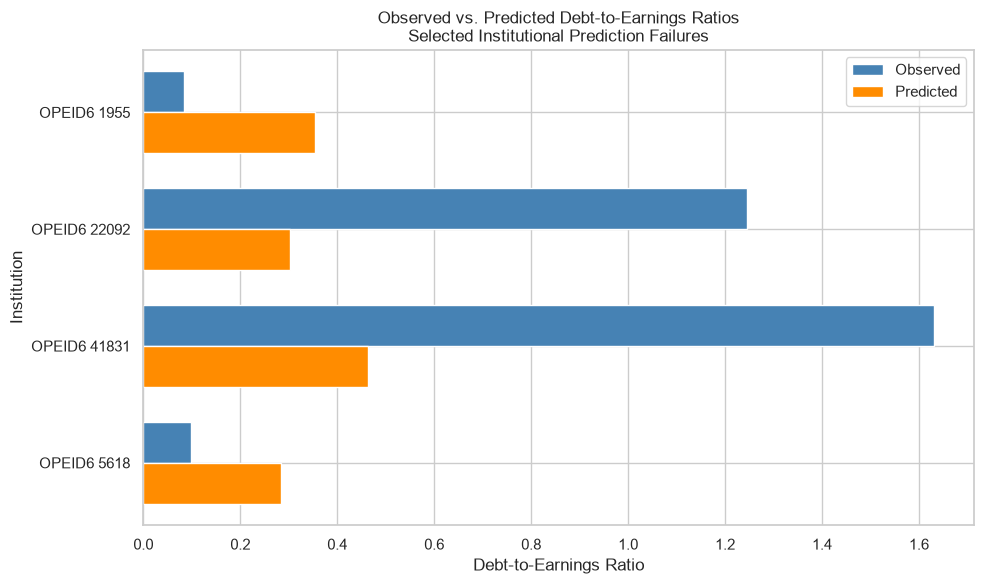

Saved figure to: ..\figures\05_final_evaluation\institutional_failure_cases.png


In [25]:

# Arrange the four failure cases by absolute prediction error
plot_cases = failure_cases.sort_values(
    "absolute_error",
    ascending=False
).copy()

# Convert identifiers to strings for readable plot labels
plot_cases["institution_label"] = (
    "OPEID6 " + plot_cases[ID_COL].astype(int).astype(str)
)

# Prepare positions for a grouped horizontal bar chart
positions = np.arange(len(plot_cases))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plot observed debt-to-earnings ratios
ax.barh(
    positions - bar_height / 2,
    plot_cases["actual_ratio"],
    height=bar_height,
    label="Observed",
    color="steelblue"
)

# Plot predicted debt-to-earnings ratios
ax.barh(
    positions + bar_height / 2,
    plot_cases["predicted_ratio"],
    height=bar_height,
    label="Predicted",
    color="darkorange"
)

# Label each institution
ax.set_yticks(positions)
ax.set_yticklabels(plot_cases["institution_label"])

# Place the largest error at the top
ax.invert_yaxis()

ax.set_xlabel("Debt-to-Earnings Ratio")
ax.set_ylabel("Institution")
ax.set_title(
    "Observed vs. Predicted Debt-to-Earnings Ratios\n"
    "Selected Institutional Prediction Failures"
)

ax.legend()

plt.tight_layout()

# Save the figure for the final report
figure_path = FIGURES_DIR / "institutional_failure_cases.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", figure_path)


## 9. Final Results Summary

This section consolidates the main findings from the final held-out evaluation, subgroup analysis, feature sensitivity assessment, robustness analysis, and institutional failure investigation.

The selected supervised-only LightGBM model was evaluated on 660 previously held-out institutions using 35 institutional predictors.

The final evaluation addresses three questions:

1. How accurately does the selected model predict institutional debt burden on unseen data?
2. Does predictive performance vary across institutional characteristics?
3. What do feature sensitivity and individual prediction failures reveal about the model's limitations?

The results provide the quantitative evidence needed to support the final Milestone II project report.

In [26]:

# Consolidate the final held-out evaluation metrics and bootstrap intervals
final_results_summary = bootstrap_summary.copy()

# Add descriptive metric names
metric_names = {
    "RMSE": "Root Mean Squared Error",
    "MAE": "Mean Absolute Error",
    "R2": "R-squared"
}

final_results_summary["metric_name"] = (
    final_results_summary["metric"].map(metric_names)
)

# Reorder columns for a report-ready table
final_results_summary = final_results_summary[
    [
        "metric_name",
        "test_estimate",
        "ci_lower_95",
        "ci_upper_95"
    ]
]

print("FINAL HELD-OUT MODEL PERFORMANCE")
display(final_results_summary.round(4))

# Summarize the highest-error subgroups
subgroup_summary = pd.DataFrame([
    {
        "dimension": "Institutional Control",
        "highest_error_group": control_metrics.loc[
            control_metrics["rmse"].idxmax(), "group"
        ],
        "highest_group_rmse": control_metrics["rmse"].max()
    },
    {
        "dimension": "Predominant Degree",
        "highest_error_group": degree_metrics.loc[
            degree_metrics["rmse"].idxmax(), "group"
        ],
        "highest_group_rmse": degree_metrics["rmse"].max()
    },
    {
        "dimension": "Undergraduate Enrollment",
        "highest_error_group": enrollment_metrics.loc[
            enrollment_metrics["rmse"].idxmax(), "group"
        ],
        "highest_group_rmse": enrollment_metrics["rmse"].max()
    }
])

print("\nHIGHEST-ERROR INSTITUTIONAL SUBGROUPS")
display(subgroup_summary.round(4))

# Save both summary tables
final_results_summary.to_csv(
    RESULTS_DIR / "final_results_summary.csv",
    index=False
)

subgroup_summary.to_csv(
    RESULTS_DIR / "highest_error_subgroups.csv",
    index=False
)

print("\nFinal summary tables saved successfully.")

FINAL HELD-OUT MODEL PERFORMANCE


,metric_name,test_estimate,ci_lower_95,ci_upper_95
0,Root Mean Squared Error,0.2809,0.2530,0.3069
1,Mean Absolute Error,0.1922,0.1763,0.2064
2,R-squared,0.5825,0.5163,0.6418



HIGHEST-ERROR INSTITUTIONAL SUBGROUPS


,dimension,highest_error_group,highest_group_rmse
0,Institutional Control,Private for-profit,0.3746
1,Predominant Degree,Certificate,0.3632
2,Undergraduate Enrollment,Q1: Smallest,0.4115



Final summary tables saved successfully.



## 10. Conclusions and Limitations

### 10.1 Main Findings

The selected supervised-only LightGBM model achieved a held-out RMSE of 0.280856, MAE of 0.192237, and R² of 0.582527 across 660 institutions.

These results were generally consistent with the training-set cross-validation estimates, suggesting that the model provides useful predictive performance on previously unseen institutions from the held-out sample.

Although cluster-derived features and PCA representations produced small numerical improvements during cross-validation, none satisfied the improvement criterion established in Notebook 4. The simpler supervised-only LightGBM model was therefore retained for final evaluation.

### 10.2 Subgroup Differences

Prediction accuracy varied substantially across institutional characteristics.

Private for-profit institutions exhibited higher RMSE than public and private nonprofit institutions. Certificate-predominant institutions also had larger prediction errors than bachelor's-predominant institutions.

The strongest subgroup pattern involved undergraduate enrollment. The smallest enrollment quartile had an RMSE of 0.4115, compared with 0.1853 for the largest quartile.

These results suggest that aggregate performance metrics conceal important differences in predictive accuracy across institutional subgroups.

### 10.3 Feature Sensitivity

Permutation importance indicated that the federal loan recipient share (`PCTFLOAN`) was the most influential individual predictor, followed by highest degree offered (`HIGHDEG`), Asian undergraduate enrollment share (`UGDS_ASIAN`), in-state tuition (`TUITIONFEE_IN`), and Pell Grant recipient share (`PCTPELL`).

These findings describe predictive dependence rather than causal relationships. In particular, demographic predictors should not be interpreted as evidence that demographic composition causes differences in debt burden.

### 10.4 Robustness

Bootstrap resampling produced a 95% confidence interval of 0.2530–0.3069 for RMSE, 0.1763–0.2064 for MAE, and 0.5163–0.6418 for R².

These intervals suggest reasonably consistent aggregate performance under resampling of the held-out institutions, although uncertainty remains.

### 10.5 Institutional Prediction Failures

Four institutions were investigated in detail.

The largest overprediction occurred at OPEID6 1955, where the predicted debt-to-earnings ratio was approximately 4.25 times the observed value.

The largest underprediction occurred at OPEID6 22092, where the observed debt-to-earnings ratio was approximately 4.10 times the predicted value.

Two of the investigated underpredictions involved very small, private for-profit, certificate-predominant institutions, consistent with the subgroup analysis.

However, substantial overpredictions also occurred at private nonprofit and public institutions.

### 10.6 Limitations

Several limitations should be considered when interpreting these findings.

First, the analysis uses institution-level data, so predictions do not represent individual students' financial outcomes.

Second, the debt-burden target is based on the ratio of median completer debt to median earnings ten years after entry. These measures do not necessarily describe the same students or a complete picture of loan repayment.

Third, the model relies on 35 institutional predictors and may omit important program-level, student-level, geographic, and economic characteristics.

Fourth, predictive performance varies across institutional subgroups, particularly smaller, certificate-predominant, and private for-profit institutions.

Fifth, permutation importance and subgroup comparisons are descriptive and should not be interpreted causally.

Finally, the held-out evaluation and bootstrap confidence intervals describe performance within the available sample. They do not establish how accurately the model would perform for future cohorts or institutions outside the evaluated population.

### 10.7 Overall Conclusion

The project demonstrates that institutional characteristics can provide meaningful predictive information about college debt burden.

The supervised-only LightGBM model achieved an R² of approximately 0.583 on held-out data, outperforming simpler approaches during model development.

However, the subgroup and failure analyses demonstrate that overall predictive performance does not guarantee equally accurate predictions across different types of institutions.

The results support using the model as an exploratory tool for understanding institutional patterns in debt burden, rather than as a definitive assessment of any individual institution or student's financial outcomes.